# Canopy Segments: Development Notebook

Use this notebook to verify the environment, test each function in `src/segments.py` as the function is written, and run the experiments behind the decisions in the README. The DAG calls the same functions, so a function that works here works in the pipeline.

# Step 0: Verify the Environment

Run these cells first, before writing any code. Each cell must run without an error. Report the result as the assignment directs.

In [1]:
import sys, pandas, sklearn, matplotlib
print("Python      ", sys.version.split()[0])
print("pandas      ", pandas.__version__)
print("scikit-learn", sklearn.__version__)
print("matplotlib  ", matplotlib.__version__)

Python       3.12.16
pandas       2.3.3
scikit-learn 1.8.0
matplotlib   3.11.2


In [2]:
!airflow version

2026-11-27T16:08:20.990870Z [info     ] setup plugin alembic.autogenerate.schemas [alembic.runtime.plugins] loc=plugins.py:37
2026-11-27T16:08:20.991122Z [info     ] setup plugin alembic.autogenerate.tables [alembic.runtime.plugins] loc=plugins.py:37
2026-11-27T16:08:20.991271Z [info     ] setup plugin alembic.autogenerate.types [alembic.runtime.plugins] loc=plugins.py:37
2026-11-27T16:08:20.991403Z [info     ] setup plugin alembic.autogenerate.constraints [alembic.runtime.plugins] loc=plugins.py:37
2026-11-27T16:08:20.991532Z [info     ] setup plugin alembic.autogenerate.defaults [alembic.runtime.plugins] loc=plugins.py:37
2026-11-27T16:08:20.991671Z [info     ] setup plugin alembic.autogenerate.comments [alembic.runtime.plugins] loc=plugins.py:37
3.1.7


In [3]:
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = ROOT / "data" / "canopy_customers.csv"
print(data_path, "exists:", data_path.exists())

/workspaces/canopy-segments/data/canopy_customers.csv exists: True


# Setup

The autoreload lines reload `segments.py` every time a cell runs, so edits to the file take effect without restarting the notebook.

In [5]:
%load_ext autoreload
%autoreload 2
sys.path.insert(0, str(ROOT / "src"))
import segments as s

customers = s.load_customers(data_path)
customers.head()

,customer_id,orders_per_year,avg_order_value,days_since_last_order,categories_purchased,discount_share,return_rate,tenure_months
0,C10001,7,36.84,22,4,0.82,0.07,26
1,C10002,1,44.76,12,3,0.31,0.02,6
2,C10003,4,56.55,333,3,0.39,0.12,18
3,C10004,10,31.23,50,6,0.67,0.08,6
4,C10005,6,41.38,12,5,0.90,0.06,33


# Test Each Function

Write tests for each function as the function is written. Decide what correct output looks like before running each test. The first test is an example: the test only prints results.

## scale_features

In [7]:
X = s.scale_features(customers)
print("shape:", X.shape)
print("min of each feature:", X.min(axis=0).round(2))
print("max of each feature:", X.max(axis=0).round(2))

#check the output type, dimensions, and range
import numpy as np

assert isinstance(X, np.ndarray)
assert X.shape == (len(customers), len(s.FEATURES))
assert np.isfinite(X).all()
assert np.all(X >= -1e-10)
assert np.all(X <= 1 + 1e-10)

print("PASS: Scaling returns seven finite features per customer within 0–1.")

shape: (1500, 7)
min of each feature: [0. 0. 0. 0. 0. 0. 0.]
max of each feature: [1. 1. 1. 1. 1. 1. 1.]
PASS: Scaling returns seven finite features per customer within 0–1.


## fit_kmeans

In [9]:
#Using k=4 to test fitting
model = s.fit_kmeans(X, k=4)

print("Cluster centers:", model.cluster_centers_.shape)
print("Customers assigned:", len(model.labels_))
print("Cluster labels:", np.unique(model.labels_))

assert model.cluster_centers_.shape == (4, 7)
assert len(model.labels_) == len(customers)
assert set(model.labels_) == {0, 1, 2, 3}
assert model.n_init == s.N_INIT
assert model.random_state == s.RANDOM_STATE

print("PASS: K-means fitted four clusters and assigned every customer.")

Cluster centers: (4, 7)
Customers assigned: 1500
Cluster labels: [0 1 2 3]
PASS: K-means fitted four clusters and assigned every customer.


## evaluate_k

In [14]:
k_evaluation = s.evaluate_k(X)
display(k_evaluation)

assert k_evaluation.columns.tolist() == ["k", "avg_distance_to_center", "silhouette"]
assert k_evaluation["k"].tolist() == [4,5,6,7]
assert k_evaluation["avg_distance_to_center"].ge(0).all()
assert k_evaluation["silhouette"].between(-1,1).all()
print("PASS: All four candidate k values have valid evaluation results.")

,k,avg_distance_to_center,silhouette
0,4,0.3151,0.4445
1,5,0.2572,0.5052
2,6,0.2501,0.4311
3,7,0.2449,0.3818


PASS: All four candidate k values have valid evaluation results.


## assign_clusters

In [16]:
assignments = s.assign_clusters(customers, X, k=5)
display(assignments.head())

assert assignments.columns.tolist() == ["customer_id", "cluster"]
assert len(assignments) == len(customers)
assert assignments["customer_id"].equals(customers["customer_id"])
assert set(assignments["cluster"]) == set(range(5))

print("PASS: Every customer has a cluster label from 0 to 4.")

,customer_id,cluster
0,C10001,1
1,C10002,4
2,C10003,3
3,C10004,1
4,C10005,1


PASS: Every customer has a cluster label from 0 to 4.


## profile_clusters

In [24]:
customer_clusters = customers.merge(
    assignments,
    on="customer_id",
    validate="one_to_one",
)
display(customer_clusters.head())
print("Customers after merge:", len(customer_clusters))

cluster_averages = (
    customer_clusters.groupby("cluster")[s.FEATURES]
    .mean()
    .round(2)
)

display(cluster_averages)


# Count rows in each cluster.
cluster_counts = customer_clusters.groupby("cluster").size()
cluster_counts = cluster_counts.rename("customers")

# Combine counts and averages using their shared cluster index.
profile = cluster_counts.to_frame().join(cluster_averages)

# Turn the cluster index into a regular column and sort the rows.
profile = profile.reset_index().sort_values("cluster")

display(profile)
assert profile["customers"].sum() == len(customers)

,customer_id,orders_per_year,avg_order_value,days_since_last_order,categories_purchased,discount_share,return_rate,tenure_months,cluster
0,C10001,7,36.84,22,4,0.82,0.07,26,1
1,C10002,1,44.76,12,3,0.31,0.02,6,4
2,C10003,4,56.55,333,3,0.39,0.12,18,3
3,C10004,10,31.23,50,6,0.67,0.08,6,1
4,C10005,6,41.38,12,5,0.90,0.06,33,1


Customers after merge: 1500


,orders_per_year,avg_order_value,days_since_last_order,categories_purchased,discount_share,return_rate,tenure_months
cluster,,,,,,,
0,5.94,69.88,47.18,1.05,0.20,0.25,36.27
1,8.93,34.89,28.44,4.05,0.75,0.07,30.01
2,13.92,96.78,20.37,6.06,0.10,0.04,48.33
3,2.02,54.94,307.76,2.11,0.30,0.10,38.80
4,3.02,59.22,15.99,2.09,0.36,0.05,3.41


,cluster,customers,orders_per_year,avg_order_value,days_since_last_order,categories_purchased,discount_share,return_rate,tenure_months
0,0,299,5.94,69.88,47.18,1.05,0.20,0.25,36.27
1,1,348,8.93,34.89,28.44,4.05,0.75,0.07,30.01
2,2,300,13.92,96.78,20.37,6.06,0.10,0.04,48.33
3,3,298,2.02,54.94,307.76,2.11,0.30,0.10,38.80
4,4,255,3.02,59.22,15.99,2.09,0.36,0.05,3.41


In [25]:
import pandas as pd
actual_profile = s.profile_clusters(customers, assignments)

# Compare the function with the table built in the notebook.
pd.testing.assert_frame_equal(actual_profile, profile)

assert actual_profile.columns.tolist() == [
    "cluster", "customers", *s.FEATURES
]
assert actual_profile["customers"].sum() == len(customers)

print("PASS: Cluster profiles match the notebook calculations.")

PASS: Cluster profiles match the notebook calculations.


## train_surrogate

In [26]:
surrogate_tree = s.train_surrogate(customers, assignments, depth=3)

assert surrogate_tree.get_depth() <= 3
assert surrogate_tree.n_features_in_ == len(s.FEATURES)
assert set(surrogate_tree.classes_) == set(assignments["cluster"])

print("PASS: Surrogate tree fitted using seven features and five cluster labels.")

PASS: Surrogate tree fitted using seven features and five cluster labels.


## agreement

In [27]:
agreement_depth3 = s.agreement(surrogate_tree, customers, assignments)

print("Depth-3 agreement:", agreement_depth3)
assert 0 <= agreement_depth3 <= 1

# Confirm agreement does not depend on assignment row order.
shuffled_assignments = assignments.sample(frac=1, random_state=0)
shuffled_agreement = s.agreement(
    surrogate_tree, customers, shuffled_assignments
)
assert np.isclose(agreement_depth3, shuffled_agreement)

print("PASS: Agreement is within 0–1 and assignments are matched by customer ID.")

Depth-3 agreement: 0.822
PASS: Agreement is within 0–1 and assignments are matched by customer ID.


## tree_rules

In [28]:
rules_depth3 = s.tree_rules(surrogate_tree)
print(rules_depth3)

# Check that the function returns nonempty text with readable feature names.
assert isinstance(rules_depth3, str)
assert rules_depth3.strip()
assert any(name in rules_depth3 for name in s.FEATURES)
assert "class:" in rules_depth3

print("PASS: Tree rules are returned as readable text.")

|--- discount_share <= 0.57
|   |--- days_since_last_order <= 112.50
|   |   |--- return_rate <= 0.11
|   |   |   |--- class: 2
|   |   |--- return_rate >  0.11
|   |   |   |--- class: 0
|   |--- days_since_last_order >  112.50
|   |   |--- discount_share <= 0.55
|   |   |   |--- class: 3
|   |   |--- discount_share >  0.55
|   |   |   |--- class: 3
|--- discount_share >  0.57
|   |--- tenure_months <= 5.00
|   |   |--- categories_purchased <= 2.50
|   |   |   |--- class: 4
|   |   |--- categories_purchased >  2.50
|   |   |   |--- class: 1
|   |--- tenure_months >  5.00
|   |   |--- days_since_last_order <= 155.00
|   |   |   |--- class: 1
|   |   |--- days_since_last_order >  155.00
|   |   |   |--- class: 3

PASS: Tree rules are returned as readable text.


# Experiments

The README records the team's decisions; these experiments supply the evidence.

## Choose k

Plot the average distance to center (elbow method) and the silhouette score for k = 4 to 7.

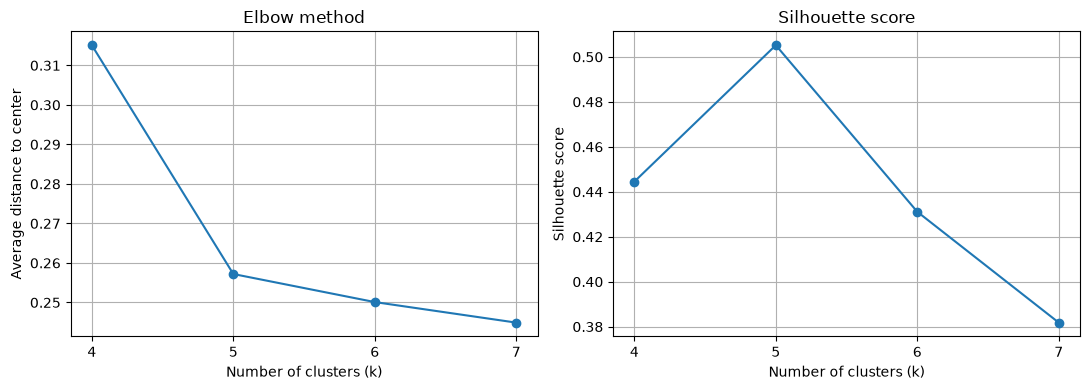

In [30]:
import matplotlib.pyplot as plt

# Plot the two measurements side by side.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    k_evaluation["k"],
    k_evaluation["avg_distance_to_center"],
    marker="o",
)
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Average distance to center")
axes[0].set_xticks(k_evaluation["k"])
axes[0].grid(True)

axes[1].plot(
    k_evaluation["k"],
    k_evaluation["silhouette"],
    marker="o",
)
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_xticks(k_evaluation["k"])
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Scaled and Unscaled Clusters

Cluster the unscaled features and compare the result with the scaled clusters. What changes, and why?

In [31]:
# Fit k-means using the original feature values.
X_unscaled = customers[s.FEATURES].to_numpy()
unscaled_assignments = s.assign_clusters(customers, X_unscaled, k=5)

# Compare customer profiles in original units.
print("Scaled cluster profiles:")
display(s.profile_clusters(customers, assignments))

print("Unscaled cluster profiles:")
display(s.profile_clusters(customers, unscaled_assignments))

# Compare the groupings without depending on cluster label numbers.
from sklearn.metrics import adjusted_rand_score

comparison = assignments.merge(
    unscaled_assignments,
    on="customer_id",
    suffixes=("_scaled", "_unscaled"),
    validate="one_to_one",
)

ari = adjusted_rand_score(
    comparison["cluster_scaled"],
    comparison["cluster_unscaled"],
)
print("Adjusted Rand index:", round(ari, 4))

# Show how customers move between the two groupings.
display(pd.crosstab(
    comparison["cluster_scaled"],
    comparison["cluster_unscaled"],
))

Scaled cluster profiles:


,cluster,customers,orders_per_year,avg_order_value,days_since_last_order,categories_purchased,discount_share,return_rate,tenure_months
0,0,299,5.94,69.88,47.18,1.05,0.20,0.25,36.27
1,1,348,8.93,34.89,28.44,4.05,0.75,0.07,30.01
2,2,300,13.92,96.78,20.37,6.06,0.10,0.04,48.33
3,3,298,2.02,54.94,307.76,2.11,0.30,0.10,38.80
4,4,255,3.02,59.22,15.99,2.09,0.36,0.05,3.41


Unscaled cluster profiles:


,cluster,customers,orders_per_year,avg_order_value,days_since_last_order,categories_purchased,discount_share,return_rate,tenure_months
0,0,593,6.34,44.88,21.23,3.05,0.55,0.08,19.02
1,1,133,2.05,54.96,376.92,2.14,0.29,0.11,38.32
2,2,358,12.41,95.45,20.65,5.20,0.12,0.07,45.15
3,3,253,6.47,65.06,57.04,1.62,0.29,0.22,36.90
4,4,163,1.98,55.12,253.76,2.08,0.31,0.10,38.91


Adjusted Rand index: 0.5231


cluster_unscaled,0,1,2,3,4
cluster_scaled,,,,,
0,45,0,49,205,0
1,309,0,0,39,0
2,2,0,293,5,0
3,0,133,0,3,162
4,237,0,16,1,1


## Tree Depth

Compare surrogate trees of depth 3 and depth 4: the agreement with the clusters and the readability of the rules.

In [29]:
# Fit a depth-4 tree to explain the same k-means assignments.
tree_depth4 = s.train_surrogate(customers, assignments, depth=4)
agreement_depth4 = s.agreement(tree_depth4, customers, assignments)
rules_depth4 = s.tree_rules(tree_depth4)

# Compare agreement and the number of terminal rules (leaves).
depth_comparison = pd.DataFrame({
    "depth": [3, 4],
    "agreement": [agreement_depth3, agreement_depth4],
    "leaves": [
        surrogate_tree.get_n_leaves(),
        tree_depth4.get_n_leaves(),
    ],
})

display(depth_comparison)
print("Depth-4 rules:")
print(rules_depth4)

,depth,agreement,leaves
0,3,0.822000,8
1,4,0.983333,13


Depth-4 rules:
|--- discount_share <= 0.57
|   |--- days_since_last_order <= 112.50
|   |   |--- return_rate <= 0.11
|   |   |   |--- tenure_months <= 9.00
|   |   |   |   |--- class: 4
|   |   |   |--- tenure_months >  9.00
|   |   |   |   |--- class: 2
|   |   |--- return_rate >  0.11
|   |   |   |--- tenure_months <= 7.50
|   |   |   |   |--- class: 4
|   |   |   |--- tenure_months >  7.50
|   |   |   |   |--- class: 0
|   |--- days_since_last_order >  112.50
|   |   |--- discount_share <= 0.55
|   |   |   |--- days_since_last_order <= 149.00
|   |   |   |   |--- class: 3
|   |   |   |--- days_since_last_order >  149.00
|   |   |   |   |--- class: 3
|   |   |--- discount_share >  0.55
|   |   |   |--- avg_order_value <= 54.58
|   |   |   |   |--- class: 3
|   |   |   |--- avg_order_value >  54.58
|   |   |   |   |--- class: 4
|--- discount_share >  0.57
|   |--- tenure_months <= 5.00
|   |   |--- discount_share <= 0.69
|   |   |   |--- class: 4
|   |   |--- discount_share >  0.69
| 